# Pong with policy gradient — Assignment 1 (Part 3b, plus the Part 2 baseline)

**The whole idea in one sentence:** a small neural network plays thousands of Pong games; after every batch of games we nudge it so the moves that came before *winning* a point become more likely, and the moves that came before *losing* a point become less likely.

**How to use this notebook**

1. **Runtime → Change runtime type.** The slow part here is *playing the game* (CPU), not the neural network, so a big GPU barely helps. What matters is the number of CPU cores, which step 2 prints. If it says 2, try a runtime with more cores (High-RAM or a GPU runtime usually has more).
2. **Run the cells from top to bottom.** Step 3 asks to connect Google Drive. Progress is saved there, so nothing is lost if Colab disconnects.
3. **Part 1** uses `BASELINE = "none"`. **Part 2** uses `BASELINE = "mean"`. If Colab lets you, run two copies of this notebook at the same time (File → Save a copy in Drive), one per setting.
4. **Keep the browser tab open.** If Colab disconnects anyway, reopen the notebook and choose Runtime → Run all. Training continues from the last save.
5. **To stop training early,** press the stop button on the training cell. It saves before stopping, and you can go straight to the evaluation cell.

## 1. Install the game
`ale-py` is the Atari emulator (it already includes the Pong game file). `gymnasium` is the library that wraps games in the standard *state → action → reward* loop you learned in lesson 1.

In [1]:
!pip install -q "gymnasium[atari]>=1.1" "ale-py>=0.10"
import importlib.util, subprocess, sys
if importlib.util.find_spec("torch") is None:      # some runtimes (e.g. TPU) may not ship PyTorch
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch"], check=True)

## 2. Imports and hardware check
Look at the **CPU cores** line. We play one game per core at the same time, so more cores means faster learning.

In [ ]:
import os, time, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import clear_output
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CPU_CORES = os.cpu_count()
print(f"gymnasium {gym.__version__} | ale-py {ale_py.__version__} | torch {torch.__version__}")
print(f"CPU cores: {CPU_CORES} | neural network runs on: {DEVICE}")

# Colors for plots (blue = slot 1, orange = slot 2, aqua = slot 3 of a colorblind-checked palette)
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})

gymnasium 1.4.0 | ale-py 0.12.1 | torch 2.14.1+cpu
CPU cores: 24 | neural network runs on: cpu


Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


## 3. Save progress to Google Drive
Colab can disconnect. Saving the network and the score history to Drive means a disconnect costs minutes, not hours.

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_ROOT = "/content/drive/MyDrive/rl_hw1_pong"
except ImportError:          # running outside Colab
    SAVE_ROOT = "./rl_hw1_pong"
os.makedirs(SAVE_ROOT, exist_ok=True)
print("Results folder:", SAVE_ROOT)

Mounted at /content/drive
Results folder: /content/drive/MyDrive/rl_hw1_pong


## 4. Settings — the knobs you can turn

| Setting | Plain-language meaning |
|---|---|
| `BASELINE` | `"none"` = Part 1 (plain policy gradient). `"mean"` = Part 2: compare each move's outcome to the *average* outcome in the batch. `"value"` = Part 2 alternative: a second network learns to predict the outcome from the screen, and each move is compared to that prediction. |
| `GAMMA` | How much a point far in the future counts. With 0.99, a point 100 moves away counts about 37% as much as a point right now (0.99¹⁰⁰ ≈ 0.37). |
| `LR` | Learning rate: how big each nudge to the network is. The assignment suggests 0.01; for Pong 0.001 is much more stable (a 0.01 nudge tends to make the network always press the same button). Mention this change in your report. |
| `NUM_ENVS` | How many games run at the same time. Set automatically to the number of CPU cores (at least 4), because each game keeps one core busy. |
| `BATCH_EPISODES` | How many finished games go into each learning step. Set to match `NUM_ENVS` (at least 10), so each step learns from roughly one fresh game per slot. If the batch were much smaller than the number of parallel games, many games would be played across several network updates, and their lessons would be slightly out of date. |
| `TRAIN_HOURS` | Training stops by itself after this long. You can also stop it earlier by hand. |

In [ ]:
BASELINE       = "mean"      # Part 1: "none"   |   Part 2: "mean" (recommended) or "value"
GAMMA          = 0.99        # discount factor required by the assignment
LR             = 1e-3        # policy learning rate (Adam)
VALUE_LR       = 1e-3        # only used when BASELINE == "value"
HIDDEN         = 200         # number of hidden units in the network
NUM_ENVS       = max(4, CPU_CORES)            # games played at the same time: one per CPU core
BATCH_EPISODES = max(10, NUM_ENVS)            # games per learning step: about one fresh game per slot
TRAIN_HOURS    = 16          # automatic stop
MAX_EPISODES   = 200000      # another automatic stop (in practice TRAIN_HOURS ends training first)
SAVE_EVERY     = 5           # save to Drive every N learning steps
PLOT_EVERY     = 5           # redraw the live plot every N learning steps
SEED           = 0

ACTIONS = np.array([2, 3])   # network output 0 -> action 2 (RIGHT = paddle up), output 1 -> action 3 (LEFT = paddle down)

RUN_NAME = f"pong_pg_{BASELINE}"
RUN_DIR = os.path.join(SAVE_ROOT, RUN_NAME)
os.makedirs(RUN_DIR, exist_ok=True)
print(f"Run: {RUN_NAME} | {NUM_ENVS} games in parallel | saving to {RUN_DIR}")

Run: pong_pg_mean | 24 games in parallel | saving to /content/drive/MyDrive/rl_hw1_pong/pong_pg_mean


## 5. Turning the screen into numbers
A Pong frame is 210×160 pixels with 3 color channels. The assignment's `preprocess` function crops away the score bar, keeps every second pixel, and turns everything into 0 (background) or 1 (paddles and ball). That gives 80×80 = 6,400 numbers.

**Why we feed the *difference* of two frames:** a single still frame can't tell you which way the ball is moving. Subtracting the previous frame from the current one leaves only what moved, so the network can "see" motion. At the very first frame of a game there is no previous frame, so the input is all zeros.

`preprocess_batch` does the same thing as `preprocess`, but for all parallel games at once (much faster).

In [8]:
def preprocess(image):
    """ prepro 210x160x3 uint8 frame into 6400 (80x80) 2D float array """
    image = image[35:195] # crop
    image = image[::2,::2,0] # downsample by factor of 2
    image[image == 144] = 0 # erase background (background type 1)
    image[image == 109] = 0 # erase background (background type 2)
    image[image != 0] = 1 # everything else (paddles, ball) just set to 1
    return np.reshape(image.astype(np.float32).ravel(), [80,80])


def preprocess_batch(frames):
    """Same result as preprocess(), for a stack of frames with shape (N, 210, 160, 3).
    Returns (N, 6400) float32. Works on a copy, so the original frames are not changed."""
    img = frames[:, 35:195:2, ::2, 0].copy()
    img[img == 144] = 0
    img[img == 109] = 0
    img[img != 0] = 1
    return img.reshape(len(frames), 6400).astype(np.float32)

### Check 1 — our fast version matches the assignment's function exactly
Edge case worth noting for your report: the assignment's `preprocess` **changes the frame you pass in** (the slices are views into the original array). That's why we hand it a copy.

Identical outputs: True
Values present: [0. 1.] | share of pixels that are 'on': 0.0053
Action meanings: ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']


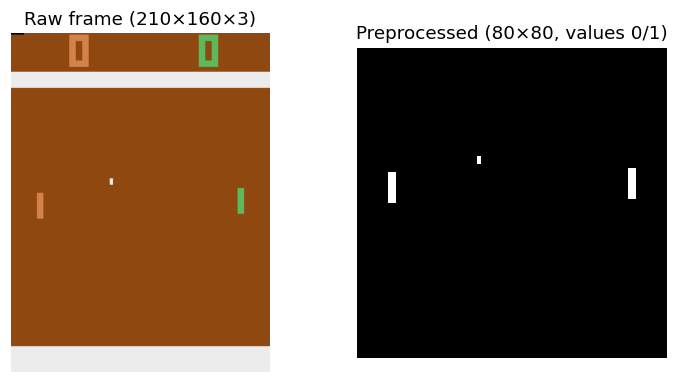

In [ ]:
env = gym.make("ALE/Pong-v5")
obs, info = env.reset(seed=SEED)
for _ in range(40):
    obs, reward, terminated, truncated, info = env.step(0)

slow = preprocess(obs.copy())
fast = preprocess_batch(obs[None])[0].reshape(80, 80)
print("Identical outputs:", np.array_equal(slow, fast))
print("Values present:", np.unique(fast), "| share of pixels that are 'on':", round(float(fast.mean()), 4))
print("Action meanings:", env.unwrapped.get_action_meanings())

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(obs); axes[0].set_title("Raw frame (210×160×3)")
axes[1].imshow(fast, cmap="gray"); axes[1].set_title("Preprocessed (80×80, values 0/1)")
for ax in axes:
    ax.axis("off"); ax.grid(False)
plt.show()
env.close()

### Check 2 — action 2 really moves the paddle up, action 3 moves it down
We switch off Pong-v5's "sticky actions" (a 25% chance the game repeats your previous move) so this test is deterministic, then track the green paddle's row on the right side of the screen. Row 0 is the top, so **up = the row number gets smaller**.

In [9]:
def paddle_row(frame80, cols=slice(70, 72)):
    rows = np.where(frame80[:, cols].any(axis=1))[0]
    return float(rows.mean()) if len(rows) else float("nan")

env = gym.make("ALE/Pong-v5", repeat_action_probability=0.0)
obs, _ = env.reset(seed=SEED)
for _ in range(20):
    obs, *_ = env.step(0)
start = paddle_row(preprocess_batch(obs[None])[0].reshape(80, 80))
rows_up, rows_down = [], []
for _ in range(8):
    obs, *_ = env.step(2)
    rows_up.append(paddle_row(preprocess_batch(obs[None])[0].reshape(80, 80)))
for _ in range(16):
    obs, *_ = env.step(3)
    rows_down.append(paddle_row(preprocess_batch(obs[None])[0].reshape(80, 80)))
env.close()

print(f"Paddle row at start: {start:.1f}")
print("Pressing action 2:", [round(r, 1) for r in rows_up])
print("Pressing action 3:", [round(r, 1) for r in rows_down])
print("Action 2 moves the paddle UP:  ", rows_up[-1] < start)
print("Action 3 moves the paddle DOWN:", rows_down[-1] > rows_up[-1])
print("(If you see nan, the paddle wasn't found in columns 70-71)")

Paddle row at start: 34.5
Pressing action 2: [29.5, 18.5, 8.5, 2.0, 1.5, 1.0, 1.0, 1.0]
Pressing action 3: [1.0, 3.5, 13.5, 23.5, 35.5, 46.5, 58.5, 69.5, 77.0, 78.0, 78.5, 78.5, 78.5, 78.5, 78.5, 78.5]
Action 2 moves the paddle UP:   True
Action 3 moves the paddle DOWN: True
(If you see nan, the paddle wasn't found in columns 70-71)


### Check 3 — how does a player that presses up/down at random score?
The score of a game is *your points minus the opponent's points*. A game ends when someone reaches 21, so scores range from −21 to +21. A random player should land around **−20 to −21**. This is our "before any learning" reference point: if the trained agent doesn't beat it, something is wrong.

In [ ]:
env = gym.make("ALE/Pong-v5")
rng = np.random.default_rng(SEED)
scores, lengths = [], []
for ep in range(3):
    obs, _ = env.reset(seed=SEED + ep)
    total, steps, done = 0.0, 0, False
    while not done:
        obs, r, terminated, truncated, _ = env.step(int(rng.choice(ACTIONS)))
        total += r; steps += 1
        done = terminated or truncated
    scores.append(total); lengths.append(steps)
env.close()
print("Random-play scores:", scores, "| decisions per game:", lengths)

Random-play scores: [-20.0, -21.0, -18.0] | decisions per game: [1043, 946, 1413]


## 6. The policy network
- **Input:** 6,400 numbers (the frame difference).
- **Hidden layer:** 200 units. Think of each one as a learned "detector", for example *ball moving toward me, below my paddle*.
- **Output:** 2 scores, turned into probabilities for *up* and *down*.

The agent doesn't always take the more likely move; it **samples** from the probabilities. That randomness is how it explores: it sometimes tries the move it currently thinks is worse, which is the only way to find out it was actually better.

The `ValueNet` is only used for `BASELINE = "value"`: same shape, but it outputs one number, its guess of how good the current situation is.

In [ ]:
class PolicyNet(nn.Module):
    def __init__(self, n_in=6400, hidden=HIDDEN, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, n_actions))

    def forward(self, x):
        return self.net(x)          # raw scores ("logits"); softmax turns them into probabilities


class ValueNet(nn.Module):
    def __init__(self, n_in=6400, hidden=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)

## 7. Discounted return ("reward-to-go")
For every move at time *t*, we add up all the rewards that came **after** it, shrinking each one by `GAMMA` per step of delay:

G_t = r_t + γ·r_{t+1} + γ²·r_{t+2} + …

A move only gets credit for what happened after it, never before. We compute this backwards from the end of the game, which takes one pass.

**Check 4:** with γ = 0.5 and rewards [0, 0, 1], the answer must be [0.25, 0.5, 1.0].

In [ ]:
def discounted_returns(rewards, gamma):
    G = np.zeros(len(rewards), dtype=np.float32)
    running = 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running
        G[t] = running
    return G

print(discounted_returns([0, 0, 1], 0.5), "  expected [0.25, 0.5, 1.0]")
print(discounted_returns([0, 0, -1, 0, 1], 0.5), "  expected [-0.1875, -0.375, -0.75, 0.5, 1.0]")

[0.25 0.5  1.  ]   expected [0.25, 0.5, 1.0]
[-0.1875 -0.375  -0.75    0.5     1.    ]   expected [-0.1875, -0.375, -0.75, 0.5, 1.0]


## 8. Playing many games at once
`Runner` keeps `NUM_ENVS` Pong games running side by side. At every step it shows all screens to the network, samples one move per game, and records *(input, move, reward)* for each game separately.

Edge cases it handles:
- **One game ends while others keep going.** That game restarts immediately, and its "previous frame" is reset so the first input of the new game is zeros. Without this, the end of one game would leak into the start of the next.
- **Games never get mixed.** Each game has its own record, and a game is only handed over for learning once it's finished.
- **Memory.** Frame differences only contain −1, 0, or 1, so they're stored as 1-byte integers (4× smaller than floats).

Small honest caveat: games still in progress when a learning step happens are finished with the updated network. With small learning steps this effect is negligible, and it's standard practice.

In [ ]:
def make_pong():
    import gymnasium as gym
    import ale_py
    gym.register_envs(ale_py)
    return gym.make("ALE/Pong-v5")


try:
    from gymnasium.vector import AutoresetMode
except ImportError:
    from gymnasium.vector.vector_env import AutoresetMode


def make_envs(n):
    # SAME_STEP: when a game ends, the returned screen is already the first screen of the next game
    return gym.vector.AsyncVectorEnv([make_pong] * n, autoreset_mode=AutoresetMode.SAME_STEP)


class Runner:
    def __init__(self, envs, seed):
        self.envs = envs
        self.n = envs.num_envs
        obs, _ = envs.reset(seed=seed)
        self.cur = preprocess_batch(obs)
        self.prev = self.cur.copy()                 # first input of each game = zeros
        self.buf = [self._empty() for _ in range(self.n)]

    @staticmethod
    def _empty():
        return {"x": [], "a": [], "r": []}

    @torch.no_grad()
    def collect(self, policy, n_episodes):
        finished = []
        while len(finished) < n_episodes:
            x = self.cur - self.prev                                  # frame difference
            logits = policy(torch.from_numpy(x).to(DEVICE))
            a_idx = torch.distributions.Categorical(logits=logits).sample().cpu().numpy()
            obs, rew, term, trunc, _ = self.envs.step(ACTIONS[a_idx])
            done = np.logical_or(term, trunc)
            for i in range(self.n):
                b = self.buf[i]
                b["x"].append(x[i].astype(np.int8))
                b["a"].append(int(a_idx[i]))
                b["r"].append(float(rew[i]))
                if done[i]:
                    finished.append({"x": np.stack(b["x"]),
                                     "a": np.array(b["a"], dtype=np.int64),
                                     "r": np.array(b["r"], dtype=np.float32)})
                    self.buf[i] = self._empty()
            new = preprocess_batch(obs)       # for finished games this is already the new game's first frame
            self.prev = np.where(done[:, None], new, self.cur)
            self.cur = new
        return finished

## 9. The learning step (this is the policy gradient)
For every move in the batch we compute **log-probability of the move × weight**, add everything up, and nudge the network to make that sum bigger. In plain language: *make each move more likely in proportion to how good its weight says it was.*

The only thing the three settings change is the **weight**:

- `"none"` (Part 1): weight = G_t, the discounted return itself. Problem: in early Pong almost every return is negative (the agent loses most points), so almost every move gets pushed down, and the useful signal is buried in noise. That's the "high variance" the assignment talks about.
- `"mean"` (Part 2): weight = (G_t − average G in the batch) ÷ spread of G. Now a move is pushed **up** if it did better than average and **down** if worse. Subtracting a constant like this doesn't change which direction is right on average, but it removes a lot of noise.
- `"value"` (Part 2 alternative): weight = G_t − V(state), where V is a second network's prediction of the return from that screen. A move gets credit only for doing better than *expected in that particular situation*.

The update is computed in chunks so that long games don't run out of memory.

In [ ]:
@torch.no_grad()
def predict_values(value_net, X, bs=8192):
    return torch.cat([value_net(X[s:s + bs].to(DEVICE).float()).cpu() for s in range(0, len(X), bs)])


def train_value(value_net, value_opt, X, G, epochs=2, bs=4096):
    n = len(G)
    last = 0.0
    for _ in range(epochs):
        perm = torch.randperm(n)
        for s in range(0, n, bs):
            idx = perm[s:s + bs]
            v = value_net(X[idx].to(DEVICE).float())
            loss = F.mse_loss(v, G[idx].to(DEVICE))
            value_opt.zero_grad(); loss.backward(); value_opt.step()
            last = loss.item()
    return last


def pg_update(policy, opt, episodes, baseline, value_net=None, value_opt=None, chunk=8192):
    X = torch.from_numpy(np.concatenate([e["x"] for e in episodes]))           # int8, stays on CPU
    A = torch.from_numpy(np.concatenate([e["a"] for e in episodes]))
    G = torch.from_numpy(np.concatenate([discounted_returns(e["r"], GAMMA) for e in episodes]))
    n_ep = len(episodes)

    stats = {}
    if baseline == "none":
        weight = G
    elif baseline == "mean":
        weight = (G - G.mean()) / (G.std() + 1e-8)
    elif baseline == "value":
        V = predict_values(value_net, X)          # prediction made BEFORE the value net sees this batch
        weight = G - V
        stats["value_loss"] = train_value(value_net, value_opt, X, G)
    else:
        raise ValueError(f"Unknown BASELINE: {baseline}")

    opt.zero_grad()
    p_up_sum, ent_sum, loss_sum = 0.0, 0.0, 0.0
    for s in range(0, len(A), chunk):
        logits = policy(X[s:s + chunk].to(DEVICE).float())
        dist = torch.distributions.Categorical(logits=logits)
        logp = dist.log_prob(A[s:s + chunk].to(DEVICE))
        loss = -(logp * weight[s:s + chunk].to(DEVICE)).sum() / n_ep   # minus sign: optimizers minimize
        loss.backward()                                                  # gradients add up across chunks
        loss_sum += loss.item()
        p_up_sum += dist.probs[:, 0].sum().item()
        ent_sum += dist.entropy().sum().item()
    opt.step()

    stats.update(loss=loss_sum, p_up=p_up_sum / len(A), entropy=ent_sum / len(A), steps=len(A))
    return stats

## 10. Helpers: plots and saving
`moving_average` averages the last 100 games at each point. For the first 99 games it averages over however many games exist so far (an edge case to mention in the report).

In [ ]:
def moving_average(x, w=100):
    x = np.asarray(x, dtype=float)
    c = np.concatenate([[0.0], np.cumsum(x)])
    idx = np.arange(len(x))
    lo = np.maximum(0, idx - w + 1)
    return (c[idx + 1] - c[lo]) / (idx + 1 - lo)


def plot_training(rewards, title, save_path=None):
    ep = np.arange(1, len(rewards) + 1)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(ep, rewards, lw=0.8, color=C_BLUE, alpha=0.35, label="Episode reward")
    ax.plot(ep, moving_average(rewards, 100), lw=2, color=C_BLUE, label="Moving average (100 episodes)")
    ax.set_xlabel("Training episode")
    ax.set_ylabel("Episode reward (points won − points lost)")
    ax.set_ylim(-21.5, 21.5)
    ax.set_title(title)
    ax.legend(loc="upper left", frameon=False)
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


CKPT_PATH = os.path.join(RUN_DIR, "checkpoint.pt")
HIST_PATH = os.path.join(RUN_DIR, "history.json")
LOG_PATH = os.path.join(RUN_DIR, "log.txt")


def save_all(policy, opt, value_net, value_opt, history, updates, train_seconds):
    state = {"policy": policy.state_dict(), "opt": opt.state_dict(),
             "value_net": value_net.state_dict() if value_net else None,
             "value_opt": value_opt.state_dict() if value_opt else None,
             "updates": updates, "train_seconds": train_seconds,
             "config": {"BASELINE": BASELINE, "GAMMA": GAMMA, "LR": LR, "HIDDEN": HIDDEN,
                        "BATCH_EPISODES": BATCH_EPISODES, "NUM_ENVS": NUM_ENVS}}
    torch.save(state, CKPT_PATH + ".tmp")
    os.replace(CKPT_PATH + ".tmp", CKPT_PATH)          # never leaves a half-written checkpoint
    with open(HIST_PATH, "w") as f:
        json.dump(history, f)

## 11. Quick trial run (about 1–3 minutes)
Before committing hours, this plays one short round with **each** baseline type using throwaway networks, so any error shows up now rather than in the middle of the night. It also measures speed.

In [ ]:
trial_envs = make_envs(min(NUM_ENVS, 4))
trial_runner = Runner(trial_envs, seed=SEED + 999)
for mode in ["none", "mean", "value"]:
    torch.manual_seed(SEED)
    p = PolicyNet().to(DEVICE)
    o = torch.optim.Adam(p.parameters(), lr=LR)
    v = ValueNet().to(DEVICE) if mode == "value" else None
    vo = torch.optim.Adam(v.parameters(), lr=VALUE_LR) if v is not None else None
    t0 = time.time()
    eps = trial_runner.collect(p, 1)
    st = pg_update(p, o, eps, mode, v, vo)
    secs = time.time() - t0
    print(f"{mode:>5}: {len(eps)} game(s), scores {[float(e['r'].sum()) for e in eps]}, "
          f"{st['steps']} decisions, p(up)={st['p_up']:.2f}, took {secs:.1f}s")
trial_envs.close()
print("\nAll three baseline types ran without errors.")

 none: 1 game(s), scores [-20.0], 919 decisions, p(up)=0.48, took 1.3s
 mean: 1 game(s), scores [-21.0], 945 decisions, p(up)=0.48, took 0.1s
value: 1 game(s), scores [-20.0], 1161 decisions, p(up)=0.48, took 0.4s

All three baseline types ran without errors.


## 12. Train
**What you'll see:** a plot that redraws every few learning steps, plus a status line.

**What to expect:**
- At first the moving average sits near **−21 to −20**: the agent loses almost every point. This can last a while. That's normal, not a bug.
- Then it slowly climbs. Improvement in Pong is gradual; think hours, not minutes.
- **`p(up)`** is the average probability of pressing up. Early on it should stay somewhere in the middle. If it gets stuck near 0.00 or 1.00 early, the network has "collapsed" into pressing one button; that usually means the learning rate is too high.

**Resuming:** if a checkpoint exists in Drive, training picks up from it automatically.

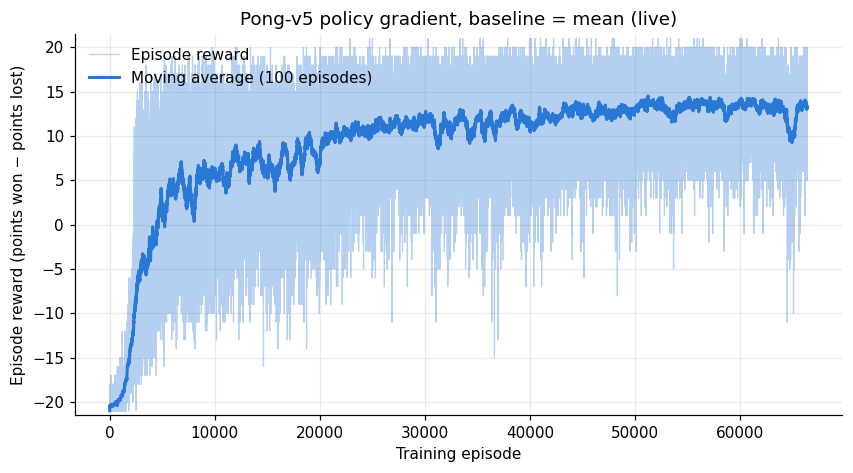

games 66367 | learning steps 2765 | last-100 avg 13.31 | best-100 avg 14.52 | p(up) 0.44 | 69.1 games/min | 16.00 h trained
Saved. games 66391 | learning steps 2766 | last-100 avg 13.28 | best-100 avg 14.52 | p(up) 0.44 | 69.1 games/min | 16.00 h trained


In [ ]:
torch.manual_seed(SEED); np.random.seed(SEED)
policy = PolicyNet().to(DEVICE)
opt = torch.optim.Adam(policy.parameters(), lr=LR)
value_net = ValueNet().to(DEVICE) if BASELINE == "value" else None
value_opt = torch.optim.Adam(value_net.parameters(), lr=VALUE_LR) if value_net is not None else None
history = {"reward": [], "length": [], "update_end_episode": [], "p_up": [], "entropy": []}
updates, train_seconds = 0, 0.0

if os.path.exists(CKPT_PATH):
    ck = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
    policy.load_state_dict(ck["policy"]); opt.load_state_dict(ck["opt"])
    if value_net is not None and ck["value_net"] is not None:
        value_net.load_state_dict(ck["value_net"]); value_opt.load_state_dict(ck["value_opt"])
    updates, train_seconds = ck["updates"], ck["train_seconds"]
    with open(HIST_PATH) as f:
        history = json.load(f)
    print(f"Resumed: {len(history['reward'])} games and {updates} learning steps already done.")

envs = make_envs(NUM_ENVS)
runner = Runner(envs, seed=SEED + updates)
session_start = time.time()
seconds_before = train_seconds

def status_line():
    r = history["reward"]
    last100 = np.mean(r[-100:]) if r else float("nan")
    best100 = max(moving_average(r, 100)[99:], default=float("nan")) if len(r) >= 100 else float("nan")
    hours = train_seconds / 3600
    per_min = len(r) / max(train_seconds / 60, 1e-9)
    return (f"games {len(r)} | learning steps {updates} | last-100 avg {last100:.2f} | best-100 avg {best100:.2f} | "
            f"p(up) {history['p_up'][-1] if history['p_up'] else float('nan'):.2f} | "
            f"{per_min:.1f} games/min | {hours:.2f} h trained")

try:
    while len(history["reward"]) < MAX_EPISODES and time.time() - session_start < TRAIN_HOURS * 3600:
        eps = runner.collect(policy, BATCH_EPISODES)
        st = pg_update(policy, opt, eps, BASELINE, value_net, value_opt)
        updates += 1
        for e in eps:
            history["reward"].append(float(e["r"].sum()))
            history["length"].append(int(len(e["r"])))
        history["update_end_episode"].append(len(history["reward"]))
        history["p_up"].append(st["p_up"]); history["entropy"].append(st["entropy"])
        train_seconds = seconds_before + (time.time() - session_start)

        if updates % SAVE_EVERY == 0:
            save_all(policy, opt, value_net, value_opt, history, updates, train_seconds)
            with open(LOG_PATH, "a") as f:
                f.write(status_line() + "\n")
        if updates % PLOT_EVERY == 0:
            clear_output(wait=True)
            plot_training(history["reward"], f"Pong-v5 policy gradient, baseline = {BASELINE} (live)")
            print(status_line())
except KeyboardInterrupt:
    print("Stopped by you.")
finally:
    train_seconds = seconds_before + (time.time() - session_start)
    save_all(policy, opt, value_net, value_opt, history, updates, train_seconds)   # save first, then clean up
    try:
        envs.close(terminate=True)
    except Exception:
        pass
    print("Saved.", status_line())

## 13. Final training plot (saved to Drive for your report)

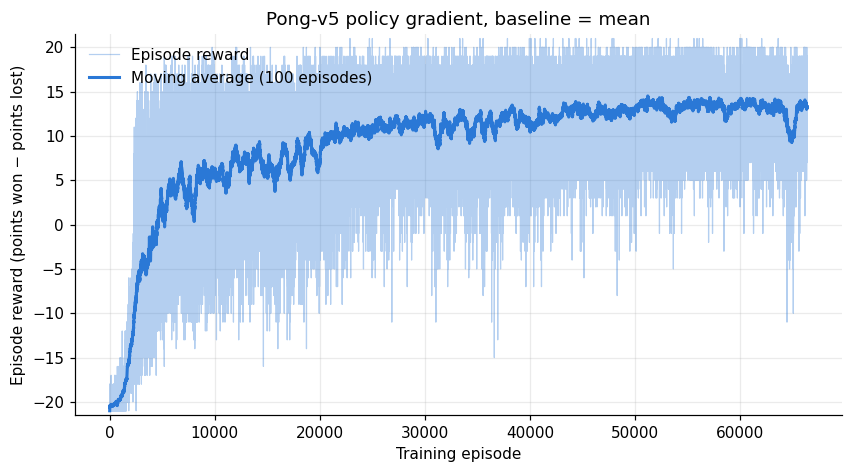

Saved: /content/drive/MyDrive/rl_hw1_pong/pong_pg_mean/training_curve.png


In [ ]:
with open(HIST_PATH) as f:
    history = json.load(f)
plot_training(history["reward"], f"Pong-v5 policy gradient, baseline = {BASELINE}",
              save_path=os.path.join(RUN_DIR, "training_curve.png"))
print("Saved:", os.path.join(RUN_DIR, "training_curve.png"))

## 14. Evaluate: 500 games with the trained agent
The agent keeps **sampling** its moves (the same way it played during training), so we're measuring the policy it actually learned. Set `GREEDY = True` to always take the more likely move instead; that's an interesting extra experiment for the report.

Edge case handled: when playing games in parallel, short games finish first. If we simply stopped at the first 500 finished games, short games would be over-represented. Instead, each parallel slot is given a fixed number of games in advance, and we wait for all of them.

  50/500 games done (0.8 min)
  100/500 games done (1.5 min)
  150/500 games done (2.1 min)
  200/500 games done (2.7 min)
  250/500 games done (3.4 min)
  300/500 games done (4.1 min)
  350/500 games done (4.7 min)
  400/500 games done (5.4 min)
  450/500 games done (6.0 min)
  500/500 games done (6.9 min)

500 games | mean 13.22 | std 3.13 | min 2 | max 21


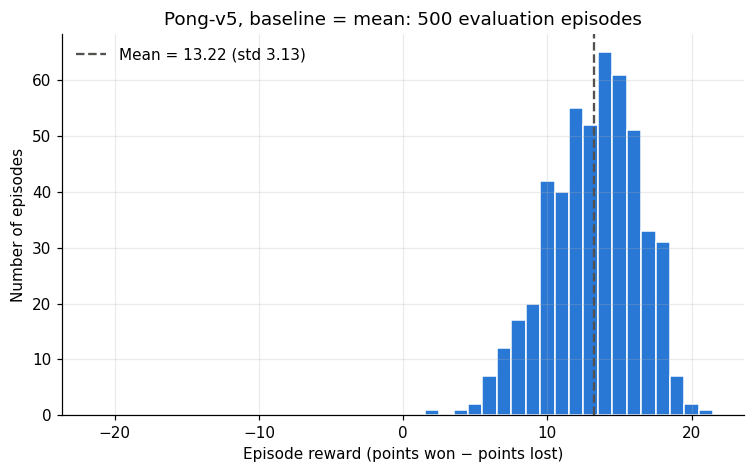

In [ ]:
EVAL_EPISODES = 500
GREEDY = False

ck = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
eval_policy = PolicyNet().to(DEVICE)
eval_policy.load_state_dict(ck["policy"]); eval_policy.eval()


@torch.no_grad()
def evaluate(policy, n_episodes, greedy=False, num_envs=NUM_ENVS, seed=12345):
    envs = make_envs(num_envs)
    quota = [n_episodes // num_envs + (1 if i < n_episodes % num_envs else 0) for i in range(num_envs)]
    results = [[] for _ in range(num_envs)]
    ep_return = np.zeros(num_envs)
    obs, _ = envs.reset(seed=seed)
    cur = preprocess_batch(obs); prev = cur.copy()
    t0, last_print = time.time(), 0
    while any(len(results[i]) < quota[i] for i in range(num_envs)):
        logits = policy(torch.from_numpy(cur - prev).to(DEVICE))
        a = logits.argmax(1) if greedy else torch.distributions.Categorical(logits=logits).sample()
        obs, r, term, trunc, _ = envs.step(ACTIONS[a.cpu().numpy()])
        ep_return += r
        done = np.logical_or(term, trunc)
        for i in np.where(done)[0]:
            if len(results[i]) < quota[i]:
                results[i].append(float(ep_return[i]))
            ep_return[i] = 0.0
        new = preprocess_batch(obs)
        prev = np.where(done[:, None], new, cur); cur = new
        n_done = sum(len(x) for x in results)
        if n_done - last_print >= 50:
            last_print = n_done
            print(f"  {n_done}/{n_episodes} games done ({(time.time() - t0) / 60:.1f} min)")
    envs.close()
    return np.array([x for res in results for x in res])


eval_rewards = evaluate(eval_policy, EVAL_EPISODES, greedy=GREEDY)
mean, std = eval_rewards.mean(), eval_rewards.std()
print(f"\n{len(eval_rewards)} games | mean {mean:.2f} | std {std:.2f} | "
      f"min {eval_rewards.min():.0f} | max {eval_rewards.max():.0f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(-21.5, 22.5, 1)
ax.hist(eval_rewards, bins=bins, color=C_BLUE, edgecolor="white", linewidth=1)
ax.axvline(mean, color="#52514e", lw=1.5, ls="--", label=f"Mean = {mean:.2f} (std {std:.2f})")
ax.set_xlabel("Episode reward (points won − points lost)")
ax.set_ylabel("Number of episodes")
ax.set_title(f"Pong-v5, baseline = {BASELINE}: {len(eval_rewards)} evaluation episodes"
             + (" (greedy)" if GREEDY else ""))
ax.legend(frameon=False)
tag = "greedy" if GREEDY else "sampled"
fig.savefig(os.path.join(RUN_DIR, f"eval_histogram_{tag}.png"), dpi=150, bbox_inches="tight")
plt.show()
with open(os.path.join(RUN_DIR, f"eval_{tag}.json"), "w") as f:
    json.dump({"rewards": eval_rewards.tolist(), "mean": float(mean), "std": float(std)}, f)

## 15. Compare Part 1 and Part 2 (run after both trainings exist)
Overlays the 100-game moving averages of every run found in your Drive folder. This is good evidence for the Part 2 question "did the baseline help?"

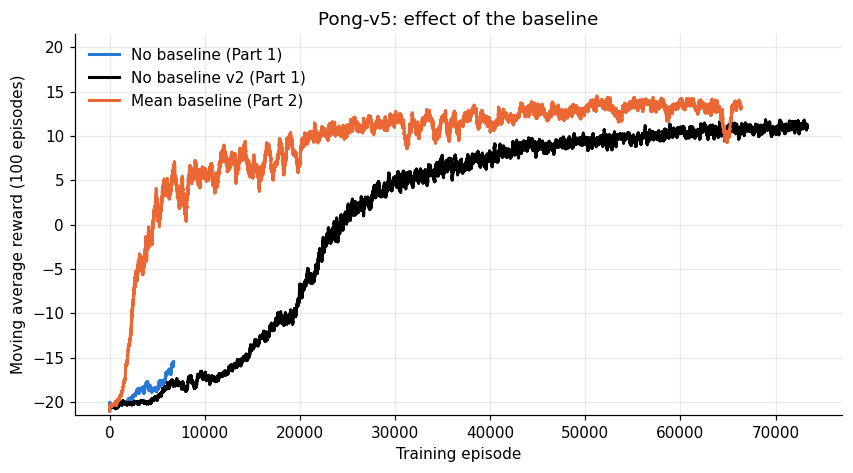

Runs found: 3


In [27]:
colors = {"none": C_BLUE, "none_2": "#000000" , "mean": C_ORANGE, "value": C_AQUA}
labels = {"none": "No baseline (Part 1)", "none_2": "No baseline v2 (Part 1)", "mean": "Mean baseline (Part 2)", "value": "Value-network baseline (Part 2)"}
fig, ax = plt.subplots(figsize=(9, 4.5))
found = 0
for name in ["none", "none_2", "mean", "value"]:
    path = os.path.join(SAVE_ROOT, f"pong_pg_{name}", "history.json")
    if os.path.exists(path):
        with open(path) as f:
            r = json.load(f)["reward"]
        ax.plot(np.arange(1, len(r) + 1), moving_average(r, 100), lw=2, color=colors[name], label=labels[name])
        found += 1
ax.set_xlabel("Training episode")
ax.set_ylabel("Moving average reward (100 episodes)")
ax.set_ylim(-21.5, 21.5)
ax.set_title("Pong-v5: effect of the baseline")
ax.legend(loc="upper left", frameon=False)
fig.savefig(os.path.join(SAVE_ROOT, "baseline_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"Runs found: {found}")